## Downloading some libraries

In [2]:
import ee
ee.Authenticate()

Exception: Problem requesting tokens. Please try again.  HTTP Error 400: Bad Request b'{\n  "error": "invalid_request",\n  "error_description": "Missing required parameter: code"\n}'

## Download Image

In [5]:
import ee
ee.Initialize()

from IPython.display import Image as Iamge_IPy
from masks import ( f_cloudMaskL457_SR,f_cloudMaskL8_SR,f_cloudMaskL8_L2,apply_scale_factors,
 f_albedoL5L7,f_albedoL8 ) 
from meteorology import get_meteorology
from tools import (fexp_spec_ind, fexp_lst_export,fexp_radlong_up, LST_DEM_correction,
fexp_radshort_down, fexp_radlong_down, fexp_radbalance, fexp_soil_heat,fexp_sensible_heat_flux,calculate_solar)
from endmembers import fexp_cold_pixel, fexp_hot_pixel
from evapotranspiration import fexp_et
import json
import geemap
import xarray as xr
import os

RefreshError: ('invalid_grant: Bad Request', {'error': 'invalid_grant', 'error_description': 'Bad Request'})

In [ ]:
def download_image(path,scale,region,image):
    geemap.ee_export_image(
        image, filename=path, scale=scale, region=region, file_per_band=True
    )

In [3]:
def plot_earth_enginer_image(image,band_name,geometry_download):
    extension = '.tif'
    path = '/app/geeSEBAL-master/Image_Downloaded/image'
    os.remove(path+'.'+band_name+extension)
    #os.mkdir('/app/geeSEBAL-master/Image_Downloaded/'+image_id)
    image_copy=image.select([band_name]) 
    download_image(path=path+extension,image=image_copy,scale=500,region=ee.Geometry.Polygon(geometry_download))
    downloaded_image = xr.open_dataset(path+'.'+band_name+extension)
    downloaded_image.band_data.plot()
    return downloaded_image

In [4]:
image_id = 'LC08_139044_20210603'
image_path = 'LANDSAT/LC08/C02/T1_L2/'+image_id
NDVI_cold=5
Ts_cold=20
NDVI_hot=10
Ts_hot=20
BASE_DIR = '/app/geeSEBAL-master'

with open(BASE_DIR+'/etbrasil/geesebal_modified/setting.json', 'r') as json_file:
            mapping  = json.load(json_file)
#GET INFORMATIONS FROM IMAGE
image = ee.Image(image_path)
_index=image.get('system:index')
cloud_cover=image.get('CLOUD_COVER')
LANDSAT_ID=image.get('LANDSAT_PRODUCT_ID').getInfo()
landsat_version= image.get('SPACECRAFT_ID').getInfo()  #'LANDSAT_8'
azimuth_angle= image.get('SUN_AZIMUTH') #calculate_solar(image)

time_start=image.get('system:time_start')
_date=ee.Date(time_start)
_year=ee.Number(_date.get('year'))
_month=ee.Number(_date.get('month'))
_day=ee.Number(_date.get('day'))
_hour=ee.Number(_date.get('hour'))
_minuts = ee.Number(_date.get('minutes'))
crs = image.projection().crs()
transform = ee.List(ee.Dictionary(ee.Algorithms.Describe(image.projection())).get('transform'))
date_string=_date.format('YYYY-MM-dd').getInfo()

#ENDMEMBERS
p_top_NDVI=ee.Number(NDVI_cold)
p_coldest_Ts=ee.Number(Ts_cold)
p_lowest_NDVI=ee.Number(NDVI_hot)
p_hottest_Ts=ee.Number(Ts_hot)

#LANDSAT IMAGE
if landsat_version == 'LANDSAT_5':
        image=image.select([0,1,2,3,4,5,6,9], ["B","GR","R","NIR","SWIR_1","BRT","SWIR_2", "pixel_qa"])
        image_toa=ee.Image('LANDSAT/LT05/C01/T1/'+ _index.getInfo())

    #GET CALIBRATED RADIANCE
        col_rad = ee.Algorithms.Landsat.calibratedRadiance(image_toa);
        col_rad = image.addBands(col_rad.select([5],["T_RAD"]))

    #CLOUD REMOTION
        image=ee.ImageCollection(image).map(f_cloudMaskL457_SR)

    #ALBEDO TASUMI ET AL. (2008)
        image=image.map(f_albedoL5L7)

elif landsat_version == 'LANDSAT_7':
        image=image.select([0,1,2,3,4,5,6,9], ["B","GR","R","NIR","SWIR_1","BRT","SWIR_2", "pixel_qa"])
        image_toa=ee.Image('LANDSAT/LE07/C01/T1/'+ _index.getInfo())

    #GET CALIBRATED RADIANCE
        col_rad = ee.Algorithms.Landsat.calibratedRadiance(image_toa);
        col_rad = image.addBands(col_rad.select([5],["T_RAD"]))

    #CLOUD REMOVAL
        image=ee.ImageCollection(image).map(f_cloudMaskL457_SR)

    #ALBEDO TASUMI ET AL. (2008)
        image=image.map(f_albedoL5L7)

else:
    print('1')
    image = apply_scale_factors(image)
    image = f_cloudMaskL8_L2(image)

    image = image.select(list(mapping.values()))
    image = image.rename(list(mapping.keys()))
    
    #image_toa=ee.Image('LANDSAT/LC08/C02/T1_L2/'+_index.getInfo())

    #GET CALIBRATED RADIANCE
    #col_rad = ee.Algorithms.Landsat.calibratedRadiance(image_toa)
    #col_rad = image.addBands(col_rad.select([9],["T_RAD"]))

    #APPLY SCALE FACTOR
    image= ee.ImageCollection(image)
    
    #ALBEDO TASUMI ET AL. (2008) METHOD WITH KE ET AL. (2016) COEFFICIENTS
    image=image.map(f_albedoL8) #image.map(f_albedoL8)

geometryReducer=image.geometry().bounds().getInfo()

#GEOMETRY
geometry_download=geometryReducer['coordinates']
camada_clip=image.select('BRT').first()

sun_elevation=ee.Number(90).subtract(azimuth_angle)

#METEOROLOGY PARAMETERS
col_meteorology= get_meteorology(image,time_start);

#AIR TEMPERATURE [C]
T_air = col_meteorology.select('AirT_G');

#WIND SPEED [M S-1]
ux= col_meteorology.select('ux_G');

#RELATIVE HUMIDITY [%]
UR = col_meteorology.select('RH_G');

#NET RADIATION 24H [W M-2]
Rn24hobs = col_meteorology.select('Rn24h_G');

#SRTM DATA ELEVATION
SRTM_ELEVATION ='USGS/SRTMGL1_003'
srtm = ee.Image(SRTM_ELEVATION).clip(geometryReducer);
z_alt = srtm.select('elevation');

#GET IMAGE
#image=image.first()

print('3')
image=image.first()
print(image.getInfo())
#SPECTRAL IMAGES (NDVI, EVI, SAVI, LAI, T_LST, e_0, e_NB, long, lat)
image=fexp_spec_ind(image)

#LAND SURFACE TEMPERATURE
image=LST_DEM_correction(image, z_alt, T_air, UR,sun_elevation,_hour,_minuts)
print(4)

#COLD PIXEL


NameError: name 'json' is not defined

**Tracing fexp_cold_pixel()**

In [7]:
refpoly = geometryReducer
#IDENTIFY THE TOP % NDVI PIXELS
d_perc_top_NDVI=image.select('NDVI_neg').reduceRegion(
    reducer=ee.Reducer.percentile([p_top_NDVI]),
    geometry= refpoly,
    scale= 30,
    maxPixels=9e14)
#GET VALUE
n_perc_top_NDVI= ee.Number(d_perc_top_NDVI.get('NDVI_neg'))


#UPDATE MASK WITH NDVI VALUES
i_top_NDVI=image.updateMask(image.select('NDVI_neg').lte(n_perc_top_NDVI))

#SELECT THE COLDEST TS FROM PREVIOUS NDVI GROUP
d_perc_low_LST = i_top_NDVI.select('LST_NW').reduceRegion(
reducer= ee.Reducer.percentile([p_coldest_Ts]),
geometry=refpoly,
scale= 30,
maxPixels=9e14)
#GET VALUE
n_perc_low_LST = ee.Number(d_perc_low_LST.get('LST_NW'))
i_cold_lst = i_top_NDVI.updateMask(i_top_NDVI.select('LST_NW').lte(n_perc_low_LST))

#FILTERS
c_lst_cold20 =  i_cold_lst.updateMask(image.select('LST_NW').gte(200))
c_lst_cold20_int=i_cold_lst.select('LST_NW').int().rename('int')
c_lst_cold20=i_cold_lst.addBands(c_lst_cold20_int)

#COUNT NUNMBER OF PIXELS
count_final_cold_pix = c_lst_cold20.select('int').reduceRegion(
    reducer=  ee.Reducer.count(),
    geometry= refpoly,
    scale= 30,
    maxPixels=9e14)
    
n_count_final_cold_pix = ee.Number(count_final_cold_pix.get('int'))

#SELECT COLD PIXEL RANDOMLY (FROM PREVIOUS SELECTION)
def function_def_pixel(f):
    return f.setGeometry(ee.Geometry.Point([f.get('longitude'), f.get('latitude')]));

fc_cold_pix = c_lst_cold20.stratifiedSample(1, "int", refpoly, 30).map(function_def_pixel)
n_Ts_cold = ee.Number(fc_cold_pix.aggregate_first('LST_NW'))
n_long_cold = ee.Number(fc_cold_pix.aggregate_first('longitude'))
n_lat_cold = ee.Number(fc_cold_pix.aggregate_first('latitude'))
n_ndvi_cold = ee.Number(fc_cold_pix.aggregate_first('NDVI'))

#CREATE A DICTIONARY WITH THOSE RESULTS
d_cold_pixel = ee.Dictionary({
        'temp': ee.Number(n_Ts_cold),
        'ndvi': ee.Number(n_ndvi_cold),
        'x': ee.Number(n_long_cold),
        'y': ee.Number(n_lat_cold),
        'sum': ee.Number(n_count_final_cold_pix)})

In [5]:
d_cold_pixel=fexp_cold_pixel(image, geometryReducer, p_top_NDVI, p_coldest_Ts)
n_Ts_cold = ee.Number(d_cold_pixel.get('temp').getInfo())
#INSTANTANEOUS OUTGOING LONG-WAVE RADIATION [W M-2]
image=fexp_radlong_up(image)

#INSTANTANEOUS INCOMING SHORT-WAVE RADIATION [W M-2]
image=fexp_radshort_down(image,z_alt,T_air,UR, sun_elevation)

#INSTANTANEOUS INCOMING LONGWAVE RADIATION [W M-2]
image=fexp_radlong_down(image, n_Ts_cold)
#INSTANTANEOUS NET RADIATON BALANCE [W M-2]
image=fexp_radbalance(image)

#SOIL HEAT FLUX (G) [W M-2]
image=fexp_soil_heat(image)
#HOT PIXEL
d_hot_pixel=fexp_hot_pixel(image, geometryReducer,p_lowest_NDVI, p_hottest_Ts)
#SENSIBLE HEAT FLUX (H) [W M-2]

In [6]:
image=fexp_sensible_heat_flux(image, ux, UR,Rn24hobs,n_Ts_cold,d_hot_pixel, date_string,geometryReducer)
#DAILY EVAPOTRANSPIRATION (ET_24H) [MM DAY-1]
image=fexp_et(image,Rn24hobs)
#NAME_FINAL=LANDSAT_ID[:5]+LANDSAT_ID[10:17]+LANDSAT_ID[17:25]
image=image.addBands([image.select('ET_24h')])

{'type': 'Image', 'bands': [{'id': 'ufric_star', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [23, 22], 'origin': [2662, 658], 'crs': 'EPSG:4326', 'crs_transform': [0.1, 0, -180.05, 0, -0.1, 90.05]}]}
{'type': 'Image', 'bands': [{'id': 'ufric_star', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [23, 22], 'origin': [2662, 658], 'crs': 'EPSG:4326', 'crs_transform': [0.1, 0, -180.05, 0, -0.1, 90.05]}]}
{'type': 'Image', 'bands': [{'id': 'ufric_star', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [23, 22], 'origin': [2662, 658], 'crs': 'EPSG:4326', 'crs_transform': [0.1, 0, -180.05, 0, -0.1, 90.05]}]}
{'type': 'Image', 'bands': [{'id': 'ufric_star', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [23, 22], 'origin': [2662, 658], 'crs': 'EPSG:4326', 'crs_transform': [0.1, 0, -180.05, 0, -0.1, 90.05]}]}
{'type': 'Image', 'bands': [{'id': 'ufric_star', 'data_type': {'type': 'PixelType', 

Image Bands used
- SAVI
- T_LST_DEM
- 

['UB',
 'B',
 'GR',
 'R',
 'NIR',
 'SWIR_1',
 'SWIR_2',
 'BRT',
 'pixel_qa',
 'ALFA',
 'NDVI',
 'EVI',
 'SAVI',
 'T_LST',
 'LAI',
 'e_0',
 'e_NB',
 'longitude',
 'latitude',
 'NDVI_neg',
 'pos_NDVI',
 'int',
 'sd_ndvi',
 'NDWI',
 'BRT_R',
 'T_LST_DEM',
 'LST_neg',
 'LST_NW',
 'Rl_up',
 'Rs_down',
 'Tao_sw',
 'ES',
 'EA',
 'Rl_down',
 'Rn',
 'G',
 'zom',
 'u_fr',
 'H',
 'rah',
 'dT',
 'rah_first',
 'zom_1',
 'u_fr_1',
 'ufric_star',
 'ET_inst',
 'ET_24h',
 'LE',
 'EF',
 'ET_24h_1']

In [24]:
for b in image.bandNames().getInfo():
    print(b)

UB
B
GR
R
NIR
SWIR_1
SWIR_2
BRT
pixel_qa
ALFA
NDVI
EVI
SAVI
T_LST
LAI
e_0
e_NB
longitude
latitude
NDVI_neg
pos_NDVI
int
sd_ndvi
NDWI
BRT_R
T_LST_DEM
LST_neg
LST_NW
Rl_up
Rs_down
Tao_sw
ES
EA
Rl_down
Rn
G
zom
u_fr
H
rah
dT
rah_first
zom_1
u_fr_1
ufric_star
ET_inst
ET_24h
LE
EF
ET_24h_1


In [21]:
for band in image.bandNames().getInfo():
    download_image(path='/app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603/LC08_139044_20210603.tif',image=image.select(band),scale=500,region=ee.Geometry.Polygon(geometry_download))

Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603
Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603
Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603
Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603
Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603
Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603
Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603
Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603
Generating URL ...
Please wait ...
Data downloaded to /app/geeSEBAL-master/Image_Downloaded/LC08

## Some Automations

In [ ]:
def f_cloudMaskL8_SR(image):
      
    quality = image.select('pixel_qa');
    c01 = quality.eq(322); #CLEAR, LOW CONFIDENCE CLOUD
    c02 = quality.eq(324); #WATER, LOW CONFIDENCE CLOUD
    c03 = quality.eq(1346);#CLEAR TERRAIN
    mask = c01.Or(c02).Or(c03);
    return image.updateMask(mask);


In [ ]:
# Define the Landsat image collection
filtered_collection = ee.ImageCollection('LANDSAT/LC08/C01/T1_SR').filterDate(
    '2019-07-15', '2033-07-16'
)

# Define a list to store image paths with valid values
valid_images = []

# Define the specific geometry coordinates for filtering
geometry_coord=ee.Geometry.Polygon([[-47.81034816465959,-16.547066330557545],
[-47.18824733458146,-16.547066330557545],
[-47.18824733458146,-16.101607931660197],
[-47.81034816465959,-16.101607931660197],
[-47.81034816465959,-16.547066330557545]])

filtered_collection = filtered_collection.filterBounds(
    geometry_coord
)

# Check if there are images in the collection
image_count = filtered_collection.size().getInfo()
print(image_count)
if image_count > 0:
    index = 0
    for path in filtered_collection.aggregate_array('system:id').getInfo():
        # Get the first image in the collection
        landsat_image = ee.Image(path)
        filtered_image = f_cloudMaskL8_SR(landsat_image)
        # Check if the image has valid values (e.g., not all zeros)
        has_valid_values = filtered_image.select('B2').reduceRegion(
            reducer=ee.Reducer.anyNonZero(),
            geometry=geometry_coord,
            scale=30,
            maxPixels=1e13
        ).getInfo()
        print(index)
        if has_valid_values['B2'] > 0:
            print(has_valid_values)
            # Save the image path in the list
            image_path = landsat_image.get('system:index').getInfo()
            valid_images.append(image_path)
        index += 1

188
0
{'B2': 1}
1
{'B2': 1}
2
{'B2': 1}
3
{'B2': 1}
4
{'B2': 1}
5
{'B2': 1}
6
{'B2': 1}
7
{'B2': 1}
8
{'B2': 1}
9
{'B2': 1}
10
{'B2': 1}
11
{'B2': 1}
12
{'B2': 1}
13
{'B2': 1}
14
{'B2': 1}
15
{'B2': 1}
16
17
18
{'B2': 1}
19
{'B2': 1}
20
{'B2': 1}
21
{'B2': 1}
22
{'B2': 1}
23
{'B2': 1}
24
{'B2': 1}
25
{'B2': 1}
26
{'B2': 1}
27
{'B2': 1}
28
29
{'B2': 1}
30
{'B2': 1}
31
{'B2': 1}
32
{'B2': 1}
33
{'B2': 1}
34
{'B2': 1}
35
{'B2': 1}
36
{'B2': 1}
37
{'B2': 1}
38
{'B2': 1}
39
{'B2': 1}
40
{'B2': 1}
41
{'B2': 1}
42
{'B2': 1}
43
{'B2': 1}
44
{'B2': 1}
45
{'B2': 1}
46
{'B2': 1}
47
48
{'B2': 1}
49
{'B2': 1}
50
{'B2': 1}
51
{'B2': 1}
52
{'B2': 1}
53
{'B2': 1}
54
{'B2': 1}
55
{'B2': 1}
56
{'B2': 1}
57
{'B2': 1}
58
59
{'B2': 1}
60
{'B2': 1}
61
{'B2': 1}
62
{'B2': 1}
63
{'B2': 1}
64
{'B2': 1}
65
66
{'B2': 1}
67
{'B2': 1}
68
{'B2': 1}
69
{'B2': 1}
70
{'B2': 1}
71
{'B2': 1}
72
{'B2': 1}
73
{'B2': 1}
74
{'B2': 1}
75
{'B2': 1}
76
{'B2': 1}
77
{'B2': 1}
78
{'B2': 1}
79
{'B2': 1}
80
{'B2': 1}
81
{'B2': 1}


In [ ]:
geometry_coord=ee.Geometry.Polygon([[-47.81034816465959,-16.547066330557545],
[-47.18824733458146,-16.547066330557545],
[-47.18824733458146,-16.101607931660197],
[-47.81034816465959,-16.101607931660197],
[-47.81034816465959,-16.547066330557545]])

In [12]:
import ee
ee.Initialize()
from IPython.display import Image as Iamge_IPy

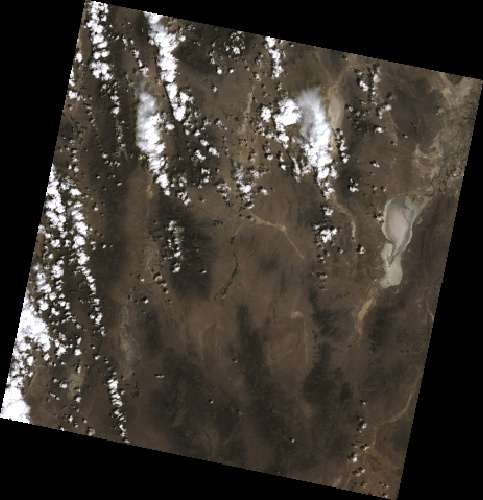

In [51]:
image = ee.Image('LANDSAT/LC08/C02/T1_L2/LC08_039033_20210521')
#RGB - Band Names: R:Red,GR:Green,B:Blue
URL_RGB=image.select(['SR_B4','SR_B3','SR_B2']).getThumbURL({
  'min': 5000,
  'max':40000,
  #'region': geometry_coord,
  #'gamma':1.5,
  'dimensions': 500,
  'format': 'jpg'
   
})

Iamge_IPy(URL_RGB,embed=True, format='jpg')

In [ ]:
neg_NDVI_band = image.select('SR_B2')
count_valid_pixels = neg_NDVI_band.gt(0).reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=geometryReducer,
    scale=30,
    maxPixels=9e14
)
print("Number of valid pixels in 'NDVI_neg' band:", count_valid_pixels.getInfo())


Number of valid pixels in 'NDVI_neg' band: {'SR_B2': 8682716.152941175}


## Extracting Appropriate Image

In [ ]:
dataset = ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').filterDate(
    '2021-05-01', '2021-06-01'
)

# Applies scaling factors.
def apply_scale_factors(image):
  optical_bands = image.select('SR_B.').multiply(0.0000275).add(-0.2)
  thermal_bands = image.select('ST_B.*').multiply(0.00341802).add(149.0)
  return image.addBands(optical_bands, None, True).addBands(
      thermal_bands, None, True
  )

dataset = dataset.map(apply_scale_factors)
image = ee.Image('LANDSAT/LC08/C02/T1_L2/LC08_039033_20210505')
image = apply_scale_factors(image)
visualization = {
    'bands': ['SR_B4', 'SR_B3', 'SR_B2'],
    'min': 0.0,
    'max': 0.3,
}

m = geemap.Map()
m.set_center(-114.2579, 38.9275, 8)
m.add_layer(image, visualization, 'True Color (432)')
m

Map(center=[38.9275, -114.2579], controls=(WidgetControl(options=['position', 'transparent_bg'], widget=Search…

In [ ]:
point_of_interest = ee.Geometry.Point(-114.2579, 38.9275)
filtered_collection = dataset.filterBounds(point_of_interest)
image_ids = filtered_collection.aggregate_array('system:index').getInfo()
print("Image IDs in the filtered collection:", image_ids)


Image IDs in the filtered collection: ['LC08_039033_20210505', 'LC08_039033_20210521']


## Read Raster Tif

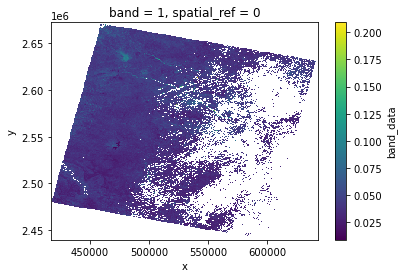

In [18]:
import xarray as xr
example = xr.open_dataset('/app/geeSEBAL-master/Image_Downloaded/LC08_139044_20210603/LC08_139044_20210603.B.tif')
example.band_data.plot()